# Training a network against a minimal dataset from the 1S shallow water surge equation

Training a Convolutional Neural Network (CNN) with data from the storm surge equation. See model_1d folder for the code that generated the data.

A simple setup for a surrogate model predicts the next time-step from the current one. This all starts from a mathematical model, which tyically involves Patial Differential Equations, but here we just collect the dynamic variables in the model in a vector $x$ at discrete times $t_0,t_1,\ldots,t_K$ and denote these as $x_k$. We can represent the numerical model as:

$x_{k+1}=M(x_k)$, starting with given initial condition $x_0$

Next, we run the numerical model and collect $x_0,x_1,\ldots,x_K$ as training data for our Machine Learning (ML) model. The aim of the ML model will be to approximate the numerical model, and we'll call it a surrogate model. It's main purpose is to have a faster but slightly less accurate version of the model. We denote the surrogate model as: 

$\hat{x}_{k+1}=\hat{M}(\hat{x}_k,\theta)$

starting with $\hat{x}_0=x_0$, which is the true initial condition.

This model has $\hat{x}_k$ as input and $x_{k+1}$ as output, and $\theta$ is a vector of parameters of the ML model to be estimated. For a given vector of parameters, one can sequentially compute $\hat{x}_1$, $\hat{x}_2$, $\hat{x}_3$, etc. This is called a rollout.

## Variables and boundary conditions in a CNN

In the mathematical notation of $x_k$ all variables are collected in a flattened vector, but for a Convolutional Neural Network that would not link nearby variables properly. Instead different variables are collected 
in a different array dimension called channels, so e.g. waterlevels $h$ and velocities $u$ are in different channels. Additional channels may be used for parameters like depth, and forcing like $\tau$.

## Training

For training the most basic approach is to use one-step-ahead predictions. This means that the target is to accurately approximate the output of the numerical model. We can write this as a loss function:

$J(\theta) = \sum_{k=1}^{K-1} | x_{k+1} - \hat{M}(x_k,\theta)|^2$

Viewed as a supervised learning method, we have the generated data $x_k$ as inputs and $x_{k+1}$ as outputs. As is common in such cases the input data are collected in an input array $X$ and an output array $Y$ that consist of:

$X=[x_0,x_1,\ldots,x_{K-1}]$
$Y=[x_1,x_2,\ldots,x_{K}]$ 

We can generalize $\hat{M}$ to matrices to obtain:

$Y \approx \hat{M}(X,\theta)$

Unfortunately there is no guarantee that reasonably accurate one-step-ahead predictions lead to accurate rollouts, since the errors can accumulate quickly.


## Important note about the default experiment in this notebook

The example in this notebook uses a very (too) small dataset. This cannot lead to good results and doesn't allow for good independence of the validation dataset. 
Because the example uses a model with few weights it still seems to work reasonably and trains in a few seconds on cpu. It is only meant to show the steps for
learning a CNN based model from the outputs of a 

In [1]:
# Initialize the Julia environment

# swithch to the directory where this script is located
cd(@__DIR__)
# Packages
using Pkg
Pkg.activate(".")

#Pkg.instantiate() # uncomment if you want to install the packages

# Load the required packages
using Flux
using BSON
using Plots, Measures
using JLD2
using ProgressMeter
using ComponentArrays

include("..//src//Surge.jl")
using .Surge  # Import all exported symbols from Surge module


# optional gpu usage
const use_gpu = false
if use_gpu
    using cuDNN, CUDA
    CUDA.allowscalar(false) # disable scalar operations on GPU
    if CUDA.functional() # check if CUDA is functional
        println("CUDA is functional, using GPU")
    else
        error("CUDA is not functional, using CPU")
    end
end

  Activating project at `c:\Users\britolim\Documents\GitHub\Surge_model\Starting_networks`


In [ ]:
# Settings

# training
n_epochs = 1000
batch_size = 50
learning_rate = 0.0001 # initial learning_rate
learning_rate_decay = 0.01 # lower learning rate at last eopch with factor
learning_rate_steps= 250 # apply every n steps
regularization_noise_level = 0.001f0 # 0.001f0 # noise level added to inputs during training
source_train_indices = collect(1:28)
source_val_indices = collect(29:34)
source_test_indices = collect(35:40)
# n_train = 250 # number of training samples, set to 1000 for faster training
# n_val = 100 # number of validation samples, set to 100 for faster training

# data
data_path = Surge.get_data_path()
model_path = Surge.get_model_path()
target_file = "72_hour_control.jld2"

# model
n_hidden = 16 # number of hidden features in the model
n_filter= 3 # width of the convolutional filter
n_input_channels = 5 # ["h", "u", "D", "tau","is_bound"]
n_output_channels = 2 # ["h", "u"]
n_state_channels = 2 # number of channels that are fed back into the model at each time step  ["h", "u"]

# results dir
results_dir = joinpath(@__DIR__, "..", "results", "main", "base_pretraining")
isdir(results_dir) || mkpath(results_dir)

# Mask parameters
masked_points_perc = 0.0      # fraction of grid points that are missing
masked_time_steps_perc = 0.0  # fraction of time steps missing at known grid points

start_step_percent = 1/1440 # fraction of time steps to skip at the beginning of the sequence during training and evaluation
end_step_percent = 1440/1440   # fraction of time steps to use at the end
nothing

In [3]:
solution, grid, times, params = Surge.load_burgers_ensemble(target_file, data_path=data_path)


X_train, Y_train, n_steps_train = Surge.prepare_training_data(solution, params)
X_val, Y_val, n_steps_val = Surge.prepare_training_data(solution, params)



(X = Float32[4.5879626f-11 0.0 … 0.12419032 1.0; 1.7875589f-10 0.0 … 0.12419032 0.0; … ; 7.320279f-37 0.0 … 0.12419032 0.0; 0.0 0.0 … 0.12419032 1.0;;; -0.0005148591 0.0 … 0.07434207 1.0; -2.2344046f-5 0.0018106779 … 0.07434207 0.0; … ; 0.0005148764 0.0018106065 … 0.07434207 0.0; 0.0 0.0 … 0.07434207 1.0;;; -0.0015190366 0.0 … 0.024282651 1.0; -0.0002785079 0.0019210544 … 0.024282651 0.0; … ; 0.0015191747 0.0019206571 … 0.024282651 0.0; 0.0 0.0 … 0.024282651 1.0;;; … ;;; 0.110604204 0.0 … -0.54764116 1.0; 0.097904816 0.02584534 … -0.54764116 0.0; … ; 1.38638 -1.180084 … -0.54764116 0.0; 0.0 0.0 … -0.54764116 1.0;;; 0.09691113 0.0 … -0.5360255 1.0; 0.08356136 0.028052162 … -0.5360255 0.0; … ; 0.8684619 -0.39045957 … -0.5360255 0.0; 0.0 0.0 … -0.5360255 1.0;;; 0.08200286 0.0 … -0.5233962 1.0; 0.06909822 0.030600566 … -0.5233962 0.0; … ; 0.8174758 0.14713706 … -0.5233962 0.0; 0.0 0.0 … -0.5233962 1.0], Y = Float32[-0.0005148591 0.0; -2.2344046f-5 0.0018106779; … ; 0.0005148764 0.001810606

In [4]:
solution_test = [copy(solution[1])]
X_test, Y_test, n_steps_test = Surge.prepare_training_data(solution_test, params)

(X = Float32[4.5879626f-11 0.0 … 0.12419032 1.0; 1.7875589f-10 0.0 … 0.12419032 0.0; … ; 7.320279f-37 0.0 … 0.12419032 0.0; 0.0 0.0 … 0.12419032 1.0;;; -0.0005148591 0.0 … 0.07434207 1.0; -2.2344046f-5 0.0018106779 … 0.07434207 0.0; … ; 0.0005148764 0.0018106065 … 0.07434207 0.0; 0.0 0.0 … 0.07434207 1.0;;; -0.0015190366 0.0 … 0.024282651 1.0; -0.0002785079 0.0019210544 … 0.024282651 0.0; … ; 0.0015191747 0.0019206571 … 0.024282651 0.0; 0.0 0.0 … 0.024282651 1.0;;; … ;;; 0.1734435 0.0 … 0.6367515 1.0; 0.18469825 0.040601335 … 0.6367515 0.0; … ; 2.107971 1.9736516 … 0.6367515 0.0; 0.0 0.0 … 0.6367515 1.0;;; 0.15218936 0.0 … 0.67272747 1.0; 0.16375464 0.041758735 … 0.67272747 0.0; … ; 3.1322951 0.61528635 … 0.67272747 0.0; 0.0 0.0 … 0.67272747 1.0;;; 0.1300452 0.0 … 0.7067925 1.0; 0.13954206 0.0448158 … 0.7067925 0.0; … ; 2.7710958 -1.5409552 … 0.7067925 0.0; 0.0 0.0 … 0.7067925 1.0], Y = Float32[-0.0005148591 0.0; -2.2344046f-5 0.0018106779; … ; 0.0005148764 0.0018106065; 0.0 0.0;;; -0.

In [5]:
# Events are split before extracting one-step samples to prevent leakage.

@show size(X_train), size(Y_train)
@show size(X_val), size(Y_val)

(size(X_train), size(Y_train)) = ((101, 5, 4320), (101, 2, 4320))
(size(X_val), size(Y_val)) = ((101, 5, 4320), (101, 2, 4320))


((101, 5, 4320), (101, 2, 4320))

In [6]:
# move data to gpu or keep on cpu
if use_gpu
    X_train = gpu(X_train)
    Y_train = gpu(Y_train)
    X_val = gpu(X_val)
    Y_val = gpu(Y_val)
else
    X_train = X_train
    Y_train = Y_train
    X_val = X_val
    Y_val = Y_val
end

# create the data loaders
train_loader, val_loader = Surge.create_data_loaders(X_train, Y_train, X_val, Y_val; batch_size)

@show train_loader
@show val_loader
nothing

train_loader = DataLoader(data::Tuple{Array{Float32, 3}, Array{Float32, 3}}, shuffle=true, batchsize=50)
val_loader = DataLoader(data::Tuple{Array{Float32, 3}, Array{Float32, 3}}, batchsize=50)


In [7]:
# Create the model

# model_cpu = Surge.build_base_cnn(n_input_channels, n_output_channels,n_hidden, n_filter, n_state_channels)
model_cpu = Chain(
    Conv((n_filter,), n_input_channels=>n_hidden, swish; pad=1),
    Conv((n_filter,), n_hidden=>n_hidden, swish; pad=1),
    Conv((n_filter,), n_hidden=>n_hidden, swish; pad=1),
    Conv((n_filter,), n_hidden=>n_hidden, swish; pad=1),
    Conv((n_filter,), n_hidden=>n_output_channels ; pad=1) # no activation in the last layer
)

model_cpu = Surge.ResidualBlock(model_cpu,2)
# Show the model strucure and number of parameters
@show model_cpu

# Move model to gpu or keep on cpu
if use_gpu
    model = gpu(model_cpu)
else
    model = model_cpu
end

model_cpu = ResidualBlock(Chain(Conv((3,), 5 => 16, swish, pad=1), Conv((3,), 16 => 16, swish, pad=1), Conv((3,), 16 => 16, swish, pad=1), Conv((3,), 16 => 16, swish, pad=1), Conv((3,), 16 => 2, pad=1)), 2)


ResidualBlock(
  Chain(
    Conv((3,), 5 => 16, swish, pad=1),  # 256 parameters
    Conv((3,), 16 => 16, swish, pad=1),  # 784 parameters
    Conv((3,), 16 => 16, swish, pad=1),  # 784 parameters
    Conv((3,), 16 => 16, swish, pad=1),  # 784 parameters
    Conv((3,), 16 => 2, pad=1),         # 98 parameters
  ),
  2,
)                   # Total: 10 arrays, 2_706 parameters, 11.328 KiB.

In [8]:
# Train the model

history = Surge.train_model!(model, train_loader, X_val, Y_val, learning_rate_steps, learning_rate_decay; regularization_noise_level, n_epochs, learning_rate)
train_loss = history.train_losses
val_loss = history.val_losses
@show history.best_epoch history.best_val_loss
 

Training: 100%|█████████████████████████████████████████| Time: 0:44:41


history.best_epoch = 1000
history.best_val_loss = 0.0010872999f0


0.0010872999f0

In [9]:
model_save_path = joinpath(model_path, "pls_be_good_v2.bson")
Surge.save_model(model_save_path, model)
# model_cpu = Surge.load_model(joinpath(model_path, "source_surge_model_10_forcings_pretrain.bson"))

Model saved to: c:\Users\britolim\Documents\GitHub\Surge_model\src\..\Trained_models\pls_be_good_v2.bson


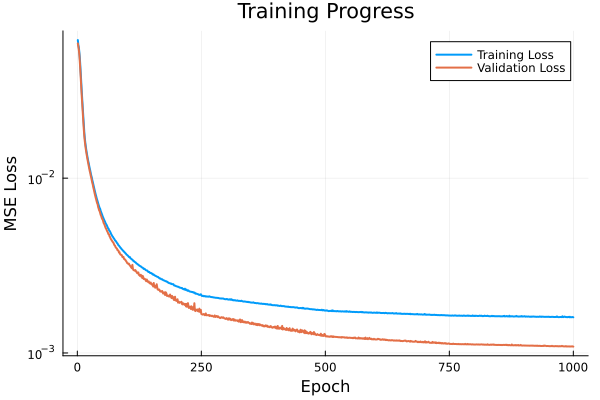

In [10]:
# Plot losses for training and validation
Surge.plot_training_curves(train_loss, val_loss)

In [11]:

# unroll the model to get the output for the initial condition
Y_unroll = Surge.unroll(model_cpu, X_test)

nothing

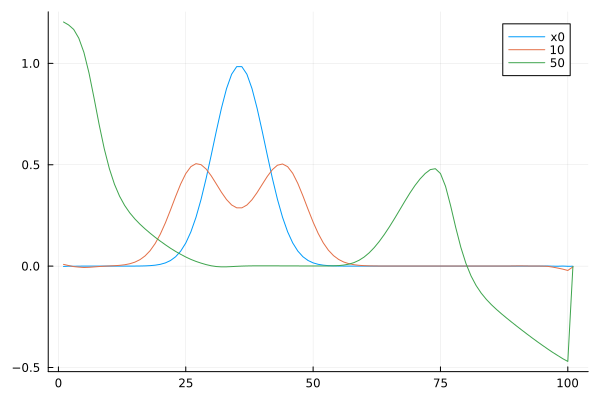

In [12]:
# plot some snapshots of the unrolled model output
plot(Y_unroll[:, 1, 1], label="x0")
plot!(Y_unroll[:,1,11], label="10")
plot!(Y_unroll[:,1,51], label="50")
#plot!(Y_unroll[:,1,101], label="100")
# plot!(Y_unroll[:,1,201], label="200")
# plot!(Y_unroll[:,1,301], label="300")

┌ Info: Saved animation to C:\Users\britolim\AppData\Local\Temp\jl_8H4PID2DyZ.gif
└ @ Plots C:\Users\britolim\.julia\packages\Plots\GIume\src\animation.jl:156


Plots.AnimatedGif("C:\\Users\\britolim\\AppData\\Local\\Temp\\jl_8H4PID2DyZ.gif")
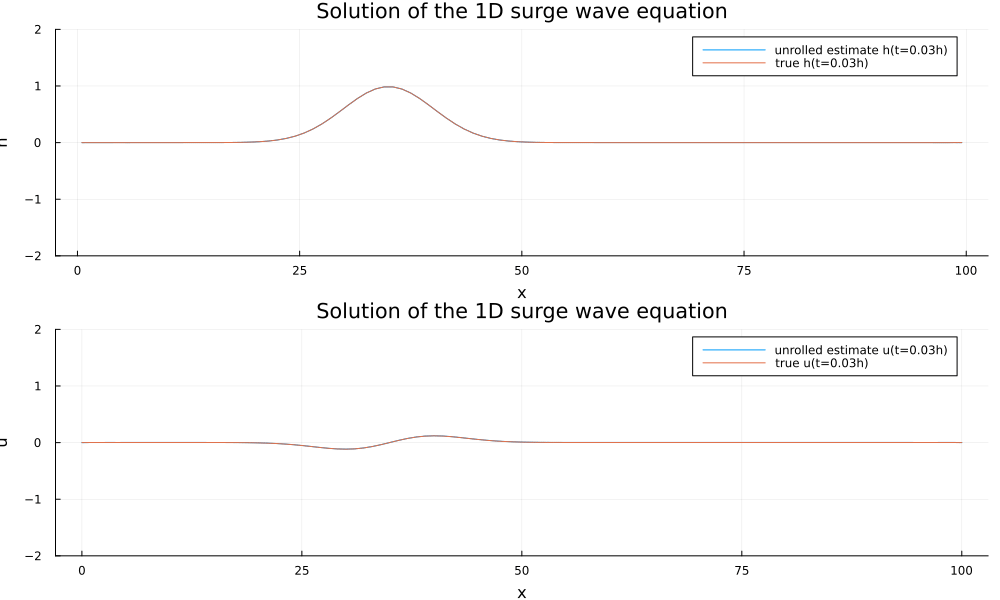

In [13]:
Surge.make_animation(Y_unroll, Y_test ,grid, times)
# length(times)

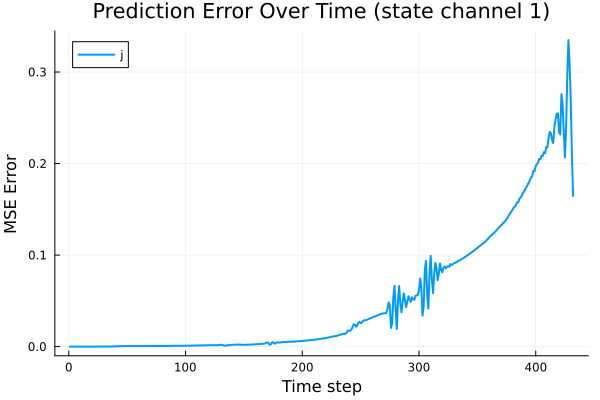

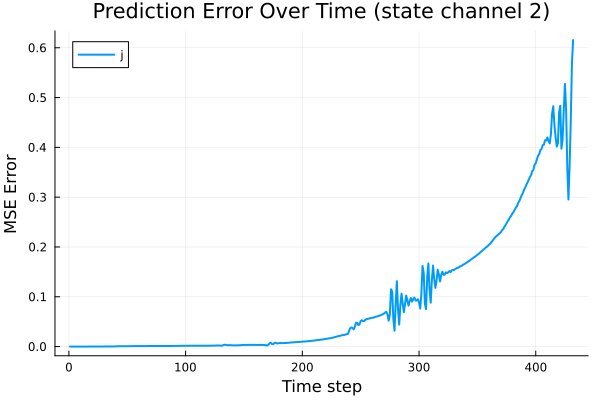

In [14]:

errors = Surge.compute_rollout_error(Y_unroll, Y_test, n_state_channels)
for ch in 1:n_state_channels
    display(Surge.plot_error_over_time(errors[ch, :], title="Prediction Error Over Time (state channel $ch)",labels = ["j" "j"]))
end

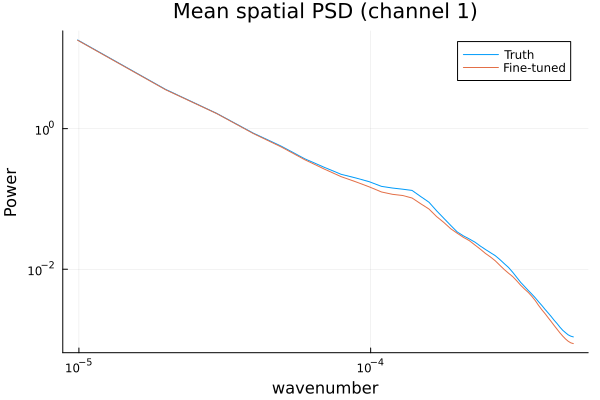

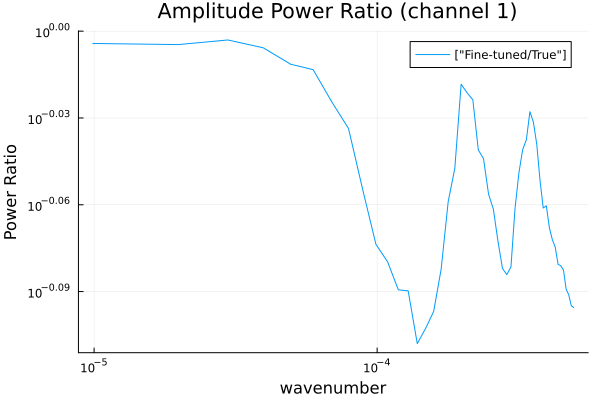

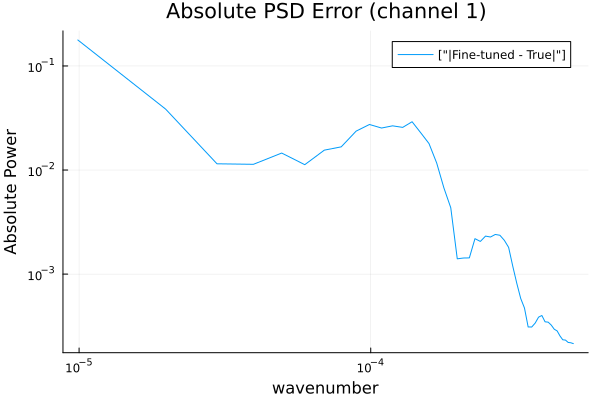

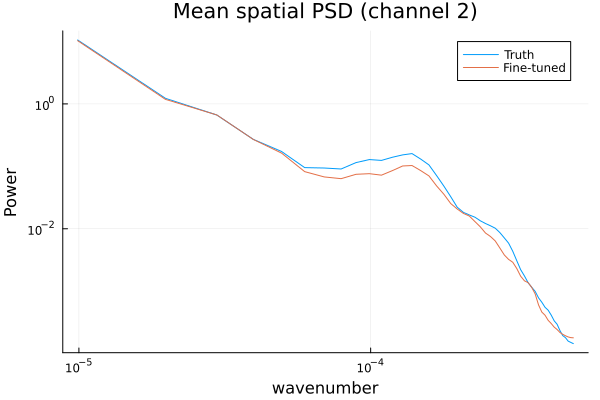

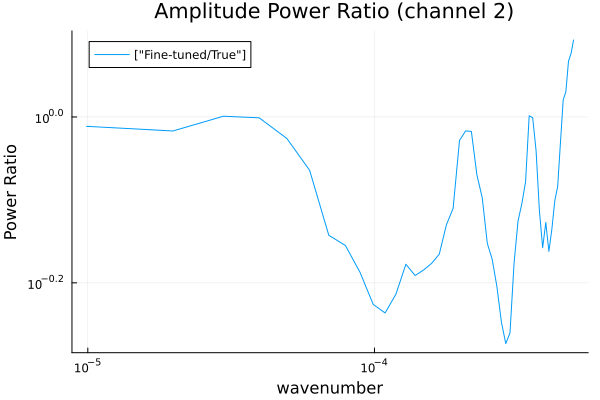

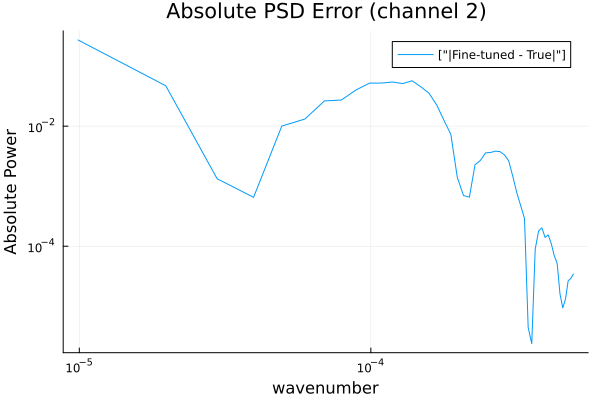

After fine-tuning:    0.026265


In [15]:

using FFTW
using Statistics

solution2 = [solution[end]]
X_test, Y_test, n_steps_test = Surge.prepare_training_data(solution2, params)
X_single_ens = X_test
Y_single_ens = Y_test
Y_val_rollout_finetuned = Surge.unroll(model, X_single_ens)
mse_val_rollout_finetuned = Flux.mse(Y_val_rollout_finetuned, Y_single_ens)

println("After fine-tuning:    $(round(mse_val_rollout_finetuned, sigdigits=6))")

n_grid = size(Y_single_ens, 1)
Δx = grid[2] - grid[1]

function mean_spatial_psd(Y, ch::Int=1; eps::Float64=1e-40)
    n_steps = size(Y,3)
    nfreq = div(n_grid, 2) + 1
    psd_acc = zeros(Float64, nfreq)
    for t in 1:n_steps
        s = Float64.(Y[:, ch, t]) .- Float64(mean(Y[:, ch, t]))
        S = abs.(rfft(s)).^2 ./ n_grid
        psd_acc .+= vec(S)
    end
    psd_mean = psd_acc ./ n_steps
    return psd_mean
end

for ch in 1:2
    psd_true = mean_spatial_psd(Y_single_ens, ch; eps=1e-40)
    psd_pred = mean_spatial_psd(Y_val_rollout_finetuned, ch; eps=1e-40)

    freqs = (0:(length(psd_true)-1)) ./ (n_grid * Δx)
    freqs_pos = freqs[2:end]

    p_psd = plot(freqs_pos, [psd_true[2:end] psd_pred[2:end]], xscale=:log10, yscale=:log10, labels=["Truth" "Fine-tuned"], xlabel="wavenumber", ylabel="Power", title="Mean spatial PSD (channel $ch)")
    display(p_psd)

    ratio_pred_true = psd_pred ./ psd_true

    display(plot(freqs_pos, [ratio_pred_true[2:end]], xscale=:log10, yscale=:log10, labels=["Fine-tuned/True"], xlabel="wavenumber", ylabel="Power Ratio", title=" Amplitude Power Ratio (channel $ch)"))

     # Absolute PSD error (Fine-tuned vs True)
    abs_error_pred_true = abs.(psd_pred .- psd_true)

    p_abs = plot(freqs_pos, [abs_error_pred_true[2:end]], xscale=:log10, yscale=:log10, labels=["|Fine-tuned - True|"], xlabel="wavenumber", ylabel="Absolute Power", title="Absolute PSD Error (channel $ch)")
    
    display(p_abs)
end
